# Validar un motor de exposición: EE analítica, convergencia y la prueba retrospectiva PIT

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 y 03 de este tema
- **Tiempo de lectura:** unos 60 minutos

**Pregunta:** ¿Es la exposición simulada del swap a 10 años internamente correcta, convergente y consistente con su forma cerrada, y sobrevive el modelo de Hull-White que la produce a la comparación con lo que el mercado entregó realmente en 309 fines de mes?

## Objetivos

Al terminar este notebook puedes:

- verificar un perfil de exposición simulado contra la forma cerrada de la swaption a la que debe ser igual, y decir por qué la verificación es una afirmación del modelo y no del mercado;
- verificar que la tasa corta simulada reprecia los bonos de descuento como martingalas, y que la EEPE y el CVA informados son los que implica el perfil;
- medir si la exposición está convergida en el número de trayectorias en unidades de error de Monte Carlo;
- correr la prueba retrospectiva de transformada integral de probabilidad del pronóstico de exposición, con un estadístico de Anderson-Darling y valores críticos simulados bajo el modelo, y leer por qué los horizontes traslapados los necesitan;
- leer el conteo de excedencias de la PFE como una prueba secundaria, y decir qué significan las luces rojas del documento versionado.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ccr import cva
from riskvalidation.ccr import exposure as ex
from riskvalidation.ccr import hw1f
from riskvalidation.ccr import swaps as sw
from riskvalidation.validation import ccr as vc
from scipy.stats import norm

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C12 (riesgo de crédito de contraparte), variante de swap único: el pagador a 10 años de 10 millones de USD del notebook 01 sobre la curva a la par del Tesoro de EE. UU. del 2025-09-30 (clase de licencia `mirror-allowed`, operación sintética, entradas de mercado reales). El documento trae las 42 filas de pruebas que el motor produjo sobre él, y un bloque de **prueba retrospectiva**: en cada uno de 309 fines de mes desde 2000-01 hasta 2025-09, el modelo se calibra solo con datos hasta esa fecha, el swap se origina a la par, se simulan 4.000 trayectorias a seis horizontes (10 y 20 días hábiles, 1, 3, 6 y 12 meses) y el valor de la cartera realizado en el horizonte, sobre la curva realmente publicada entonces, se transforma en su PIT dentro de la muestra simulada.

- **Archivos que se leen:** `data/derived/C12/single-swap.json` (las filas `tests` y el bloque de la prueba retrospectiva) y `data/derived/C12/netting-set.json` (curva, calibración y los cuatro swaps, para reconstruir la simulación).
- **Qué calcula este notebook y qué lee:** las pruebas internas se calculan aquí desde la simulación, los estadísticos PIT desde los PIT versionados. Las 309 simulaciones de 4.000 trayectorias de la prueba retrospectiva no se vuelven a correr: toman minutos y el documento versiona su resultado.

La celda siguiente carga ambos documentos y cuenta las filas de pruebas versionadas por familia y luz.

In [2]:
# Cargar los dos documentos versionados (tres carpetas bajo la raíz del repositorio) y contar las filas de pruebas
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C12"
single = json.loads((derived / "single-swap.json").read_text(encoding="utf-8"))
netting = json.loads((derived / "netting-set.json").read_text(encoding="utf-8"))
out, base = single["outputs"], netting["outputs"]
bt = out["backtest"]
print("calculado con riskvalidation", single["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
LIGHT = {"green": "verde", "red": "rojo", "amber": "ámbar"}

families = {}
for row in single["tests"]:
    key = row["test_id"].split(".")[1].split("_")[0]
    families.setdefault(key, {}).setdefault(LIGHT[row["light"]], 0)
    families[key][LIGHT[row["light"]]] += 1
for key, counts in families.items():
    print(f"  {key:15s}", counts)
print("ventana:", bt["window_start"], "a", bt["window_end"], "|", len(bt["dates"]), "fechas")
print("trayectorias por fecha:", bt["paths_per_date"])
print("PIT:", bt["pit_rule"], "|", bt["statistic"])

calculado con riskvalidation 1.0.1 | instalado 1.0.1
  ee              {'verde': 1}
  martingale      {'verde': 1}
  eepe            {'verde': 1}
  cva             {'verde': 1}
  path            {'verde': 1}
  pit             {'rojo': 12}
  pfe             {'rojo': 18}
  quantlib        {'verde': 4}
  reconcile       {'verde': 1}
  ore             {'verde': 2}
ventana: 2000-01 a 2025-09 | 309 fechas
trayectorias por fecha: 4000
PIT: (i + 1) / (N + 2) | Anderson-Darling W^2


## Método

### Paso 1: la EE analítica contra la simulada

La exposición esperada de un swap único tiene una forma cerrada. La exposición de un swap pagador en $t$ es el pago de una swaption pagadora sobre el swap restante, así que en la medida neutral al riesgo $EE_B(t) = \mathrm{Swaption}(0; t) / P(0, t)$, con la swaption valorada por la descomposición de Jamshidian del modelo de Hull-White (una opción sobre un bono cero cupón a la tasa $r^*$ que hace que el bono con cupones valga la par). La identidad vale en las fechas de reinicio del swap, así que la verificación se hace allí: 19 de las 33 fechas del informe. `analytic_ee_single_swap`, del motor, devuelve el perfil y `ee_analytic_vs_simulated` lo compara con la simulación: el estadístico es la mayor brecha en unidades de error estándar de Monte Carlo, y el umbral es 3 (un umbral interno de Contraste, no regulatorio). Comparamos la EE simulada descontada con el perfil analítico por $P(0,t)$. La celda siguiente reconstruye la simulación del notebook 01 y corre la verificación.

In [3]:
# Reconstruir la simulación del notebook 01 con la curva, la calibración, la semilla y la grilla del caso
tenors = np.array([p["tenor_years"] for p in base["curve"]["points"]])
zeros = np.array([p["zero_rate"] for p in base["curve"]["points"]])
a, sigma = base["calibration_used"]["a"], base["calibration_used"]["sigma"]
p0, forward = hw1f.curve_functions(zeros, tenors)
named = base["named_parameters"]
report = np.array(named["time_grid_years"]["value"])
main = np.concatenate([[0.0], report])
swaps = [
    sw.Swap(t["trade_id"], t["notional"]["amount"], t["fixed_rate"], t["side"] == "payer",
            t["start_years"], t["maturity_years"], t["fixed_frequency_per_year"])
    for t in base["book"]["trades"]
]
merged = np.unique(np.round(np.concatenate([main] + [main + d for d in (14 / 360, 28 / 360)]), 12))
grid = sw.simulation_grid(merged, swaps)
n_paths, seed = named["path_count"]["value"], named["seed"]["value"]
r = hw1f.simulate_short_rate(grid, a, sigma, forward, n_paths, seed)
numeraire = hw1f.bank_account(grid, r, a, sigma, p0, forward)
values = sw.swap_values_on_grid(swaps, grid, r, a, sigma, p0, forward)
ix = np.searchsorted(grid, report - sw.TIME_TOL)
p0r = p0(report)
v1, nm = values[0][:, ix], numeraire[:, ix]
ee_d, ee_d_se = ex.expected_exposure(v1, nm)
print("trayectorias:", n_paths, "| semilla:", seed, "| fechas del informe:", report.size)

trayectorias: 20000 | semilla: 42 | fechas del informe: 33


La celda siguiente calcula la EE de forma cerrada del primer swap en sus fechas de reinicio y la compara con la simulada mediante la prueba del motor.

In [4]:
# La EE analítica del swap único en sus fechas de reinicio frente a la EE simulada
swap = swaps[0]
resets = sw.reset_times(swap)
pick = [k for k, t in enumerate(report) if np.min(np.abs(resets - t)) < 1e-9]
analytic = ex.analytic_ee_single_swap(swap, report[pick], a, sigma, p0, forward)
test1 = vc.ee_analytic_vs_simulated(analytic * p0r[pick], ee_d[pick], ee_d_se[pick], 3.0)
k1, k5 = np.searchsorted(report, [1.0 - 1e-9, 5.0 - 1e-9])
ee_fwd = ee_d / p0r

print("fechas verificadas:", len(pick), "de", report.size)
print("estadístico (mayor brecha en errores estándar):", round(test1.statistic, 6))
print("mayor brecha absoluta, USD:", round(test1.metric, 1), "| luz:", LIGHT[test1.light.value])
print("EE analítica a 1 a y 5 a (medida forward):",
      np.round(analytic[[pick.index(k1), pick.index(k5)]], 0))
print("EE simulada a 1 a y 5 a:", np.round(ee_fwd[[k1, k5]], 0))

fechas verificadas: 19 de 33
estadístico (mayor brecha en errores estándar): 0.89077
mayor brecha absoluta, USD: 1161.3 | luz: verde
EE analítica a 1 a y 5 a (medida forward): [141685. 295711.]
EE simulada a 1 a y 5 a: [141414. 294524.]


La celda siguiente dibuja la EE analítica en las fechas de reinicio sobre la EE simulada, con una banda de tres errores estándar.

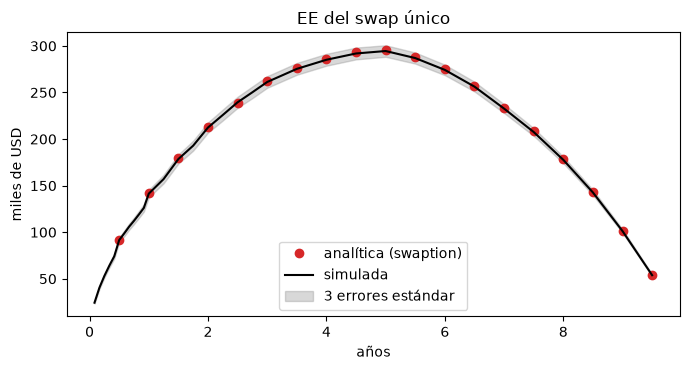

In [5]:
# Dibujar la EE analítica contra la simulada con una banda de tres errores estándar
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(report[pick], analytic / 1e3, "o", color="tab:red", label="analítica (swaption)")
ax.plot(report, ee_fwd / 1e3, color="black", lw=1.5, label="simulada")
band = 3 * ee_d_se / p0r
ax.fill_between(report, (ee_fwd - band) / 1e3, (ee_fwd + band) / 1e3, color="grey", alpha=0.3,
                label="3 errores estándar")
ax.set_xlabel("años")
ax.set_ylabel("miles de USD")
ax.set_title("EE del swap único")
ax.legend()
fig.tight_layout()
plt.show()

Los puntos rojos, uno por fecha de reinicio, quedan dentro de la banda gris alrededor de la curva negra simulada en todas las fechas, así que la forma cerrada y la simulación cuentan la misma historia y la mayor brecha es menor que un error estándar. El acuerdo es una afirmación sobre el modelo: ambos números salen de la dinámica de Hull-White, de modo que esta verificación puede detectar un error en el código, en el descuento o en las trayectorias, pero no puede decir si la dinámica de Hull-White se parece al mercado. Esa segunda pregunta es la prueba retrospectiva del Paso 4.

### Paso 2: martingalas, y los números informados

Otras dos verificaciones salen del modelo y de las definiciones.

- **Prueba de martingala.** Como el modelo reprecia la curva de hoy, el precio descontado del bono $\exp(-\int_0^t r)\,P(t, T; r_t)$ tiene media $P(0,T)$ para todo $t \le T$. `martingale_discounted_bonds`, del motor, compara la media muestral con $P(0,T)$ en errores estándar. Tomamos $T = 10$ años.
- **Recálculo.** `eepe_recomputed` reconstruye la EPE efectiva desde el perfil de EE (máximo acumulado, luego el promedio del primer año) y la compara con el número informado; `cva_recomputed` reconstruye el CVA desde la EE descontada y las probabilidades de incumplimiento. Su umbral es una diferencia relativa de $10^{-9}$. Una verificación que nunca falla no dice nada, así que la celda muestra también a cada una ponerse roja cuando el número informado está errado en 1%.

In [6]:
# La prueba de martingala del precio descontado del bono
keep = report <= 10.0 + 1e-9
means, ses = [], []
for k in np.where(keep)[0]:
    i = ix[k]
    bond = hw1f.bond_price(r[:, i], float(grid[i]), 10.0, a, sigma, p0, forward) / numeraire[:, i]
    means.append(bond.mean())
    ses.append(bond.std(ddof=1) / np.sqrt(bond.size))
p_top = float(p0(np.array(10.0)))
test2 = vc.martingale_discounted_bonds(np.array(means), np.full(len(means), p_top), np.array(ses), 3.0)
mean_5 = means[int(np.searchsorted(report, 5.0 - 1e-9))]
print("P(0,10) =", round(p_top, 6), "| media del bono descontado a 5 a:", round(mean_5, 6))
print("estadístico de martingala:", round(test2.statistic, 6),
      "| mayor brecha absoluta:", f"{test2.metric:.2e}", "|", LIGHT[test2.light.value])

P(0,10) = 0.658648 | media del bono descontado a 5 a: 0.65861
estadístico de martingala: 0.164091 | mayor brecha absoluta: 6.96e-05 | verde


La celda siguiente corre las pruebas de recálculo sobre la EEPE y el CVA informados, cada una una vez tal como se informan y otra con el número informado 1% demasiado alto.

In [7]:
# Las pruebas de recálculo de EEPE y CVA, tal como se informan y con un error de 1% para verlas fallar
ee_f = np.array(out["exposure"]["ee"]["values"])
eepe_reported = out["exposure"]["eepe"]["amount"]
cv = out["cva_dva"]
survival = np.array([b["survival"] for b in cv["buckets"]])
pd_cp = cva.default_probabilities(np.concatenate([[1.0], survival]))
epe_d = np.array(out["exposure"]["ee_discounted"]["values"])
labels = ("tal como se informa", 1.0), ("informado 1% más alto", 1.01)
for label, factor in labels:
    t3 = vc.eepe_recomputed(report, ee_f, eepe_reported * factor)
    print(f"EEPE {label:26s} diferencia relativa {t3.metric:.2e} | {LIGHT[t3.light.value]}")
for label, factor in labels:
    t4 = vc.cva_recomputed(epe_d, pd_cp, cv["lgd"], cv["cva"]["amount"] * factor)
    print(f"CVA  {label:26s} diferencia relativa {t4.metric:.2e} | {LIGHT[t4.light.value]}")

EEPE tal como se informa        diferencia relativa 0.00e+00 | verde
EEPE informado 1% más alto      diferencia relativa 1.00e-02 | rojo
CVA  tal como se informa        diferencia relativa 0.00e+00 | verde
CVA  informado 1% más alto      diferencia relativa 1.00e-02 | rojo


### Paso 3: convergencia en el número de trayectorias

El error de Monte Carlo baja como $1/\sqrt{P}$, así que un perfil está convergido cuando duplicar las trayectorias lo mueve menos que su propio error. `path_convergence`, del motor, toma el perfil de EE y el CVA con dos números de trayectorias, con el error estándar del número menor, e informa el mayor cambio en unidades de ese error; el umbral es $k_{se}=3$ para verde y $2k_{se}$ para ámbar. Una versión anterior usaba una banda unitaria sobre el coeficiente de variación, que se encendía por ruido: la EE de un swap a la par tiene un coeficiente de variación mayor que 1. Para conservar los pares antitéticos, la muestra menor toma el primer cuarto de las trayectorias y sus espejos. La celda siguiente arma las dos muestras (10.000 y 20.000 trayectorias) y corre la prueba.

In [8]:
# EE y CVA con 5.000, 10.000 y 20.000 trayectorias (conservando los pares antitéticos) y la prueba de convergencia
half = n_paths // 2
dt = np.diff(np.concatenate([[0.0], report]))
x_pos = np.maximum(v1, 0.0)
ee_by, ee_se_by, cva_by, cva_se_by = {}, {}, {}, {}
for m in (n_paths // 4, n_paths // 2, n_paths):
    idx = np.concatenate([np.arange(m // 2), half + np.arange(m // 2)])
    e_d, e_se = ex.expected_exposure(x_pos[idx], nm[idx])
    ee_by[m], ee_se_by[m] = e_d / p0r, e_se / p0r
    discounted = x_pos[idx] / nm[idx]
    cva_by[m], cva_se_by[m] = cva.wwr_cva(np.zeros((m, report.size)), discounted, survival, dt, cv["lgd"], 0.0)
test5 = vc.path_convergence(ee_by, cva_by, ee_se_by_path_count=ee_se_by, cva_se_by_path_count=cva_se_by, k_se=3.0)
for m in ee_by:
    eepe_m = ex.effective_epe(report, ex.effective_ee(ee_by[m]))
    print(f"{m:6d} trayectorias: EEPE {eepe_m:10.1f} | CVA {cva_by[m]:9.2f} +/- {cva_se_by[m]:6.2f}")
thr = test5.extras["thresholds"]
print("conteos comparados:", thr["smaller_count"], "y", thr["larger_count"])
print("mayor cambio de la EE en errores estándar:", round(test5.statistic, 6))
print("cambio del CVA en errores estándar:", round(test5.metric, 6), "| luz:", LIGHT[test5.light.value])

  5000 trayectorias: EEPE    86021.1 | CVA  10332.46 +/- 110.95
 10000 trayectorias: EEPE    87117.1 | CVA  10352.49 +/-  79.35
 20000 trayectorias: EEPE    87550.9 | CVA  10337.65 +/-  55.84
conteos comparados: 10000 y 20000
mayor cambio de la EE en errores estándar: 0.789312
cambio del CVA en errores estándar: 0.186955 | luz: verde


### Paso 4: la prueba retrospectiva PIT

Las pruebas hasta aquí verifican el modelo contra sí mismo. Una prueba retrospectiva lo verifica contra el mercado. En cada fecha $d$ el modelo da una distribución del valor de la cartera en un horizonte $h$; el mercado entrega entonces un valor realizado $v_d$. Si el modelo es correcto, la transformada integral de probabilidad

$$\mathrm{PIT}_d = \frac{i_d + 1}{N + 2}, \qquad i_d = \#\{\text{valores simulados bajo } v_d\}$$

es uniforme en $(0,1)$ entre fechas (BCBS 185, párrafo 25; la regla $(i+1)/(N+2)$ evita los valores 0 y 1). La uniformidad se mide con el estadístico de Anderson-Darling

$$W^2 = -n - \sum_{k=1}^n \frac{2k-1}{n}\,\big[\ln x_k + \ln(1 - x_{n+1-k})\big]$$

que pesa mucho las colas, donde fallan los modelos de exposición. Los valores críticos de $W^2$ para PIT uniformes independientes están tabulados (2,492 a 5%), pero las fechas de fin de mes con horizontes de 3, 6 y 12 meses **se traslapan**, así que los PIT son dependientes y la tabla independiente es demasiado indulgente. Por eso el motor pide valores críticos simulados bajo el propio modelo, con las mismas fechas y los mismos traslapes (`simulate_pit_critical_values`), e informa los independientes junto a ellos, nunca en su lugar, junto con un tamaño efectivo de muestra. La celda siguiente calcula $W^2$ y el tamaño efectivo de muestra desde los PIT versionados de los seis horizontes y los pone junto a los dos valores críticos.

In [9]:
# W^2 y el tamaño efectivo de muestra de los PIT versionados de los seis horizontes, junto a los valores críticos
horizons = bt["book_horizons"]
w2s, crits = [], []
print(f"{'horizonte':>10s}{'n':>5s}{'W2':>10s}{'ESS':>8s}{'iid 5%':>9s}{'simulado 5%':>16s}  rechaza")
for h in horizons:
    pits = np.array(h["pits"])
    w2, ess = vc.anderson_darling_w2(pits), vc.effective_sample_size(pits)
    crit = h["critical_simulated"]["p05"]
    w2s.append(w2)
    crits.append(crit)
    verdict = "sí" if w2 > crit else "no"
    print(f"{h['horizon']:>10s}{h['n']:5d}{w2:10.3f}{ess:8.1f}{h['critical_iid']['p05']:9.3f}{crit:16.3f}  {verdict}")

pits10 = np.array(horizons[0]["pits"])
above = [round(float((pits10 > q).mean()), 3) for q in (0.90, 0.95, 0.99)]
below = [round(float((pits10 < q).mean()), 3) for q in (0.10, 0.05, 0.01)]
print("parte de PIT sobre los niveles 90, 95 y 99 en el horizonte de 10 días (uniforme: 10%, 5%, 1%):", above)
print("parte de PIT bajo los niveles 10, 5 y 1:", below)
rate_w2 = vc.anderson_darling_w2(np.array(bt["risk_factor"]["horizons"][0]["pits"]))
print("la propia tasa a 3 meses, W2 en el horizonte de 10 días:", round(rate_w2, 3))

 horizonte    n        W2     ESS   iid 5%     simulado 5%  rechaza
      10bd  309   107.678   309.0    2.492           2.391  sí
      20bd  309    90.995   309.0    2.492           2.728  sí
        1m  309    89.772   309.0    2.492           2.539  sí
        3m  309    97.569   134.8    2.492           6.581  sí
        6m  309    95.896    76.5    2.492          11.813  sí
       12m  309   153.093    54.8    2.492          24.053  sí
parte de PIT sobre los niveles 90, 95 y 99 en el horizonte de 10 días (uniforme: 10%, 5%, 1%): [0.314, 0.272, 0.188]
parte de PIT bajo los niveles 10, 5 y 1: [0.288, 0.227, 0.159]
la propia tasa a 3 meses, W2 en el horizonte de 10 días: 34.769


La celda siguiente dibuja el histograma de los PIT a 10 días frente a la densidad uniforme, y el $W^2$ de cada horizonte frente a su valor crítico simulado de 5%.

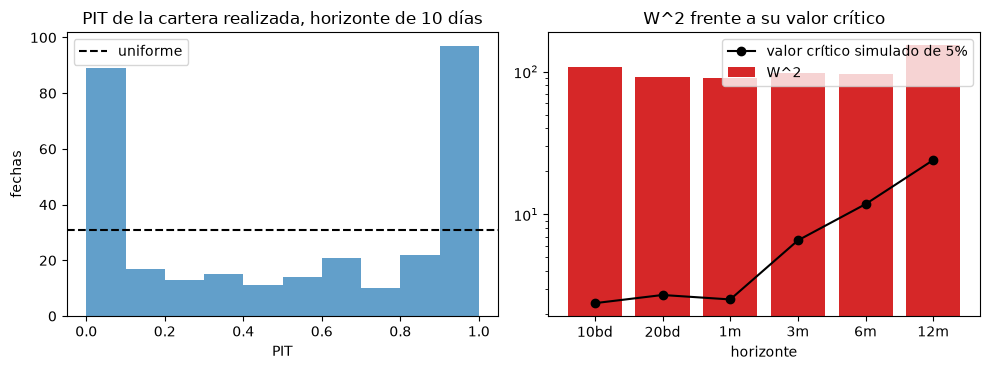

In [10]:
# Dibujar el histograma de los PIT a 10 días (izquierda) y W^2 contra su valor crítico por horizonte (derecha)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
left.hist(pits10, bins=10, range=(0, 1), color="tab:blue", alpha=0.7)
left.axhline(len(pits10) / 10, color="black", ls="--", label="uniforme")
left.set_xlabel("PIT")
left.set_ylabel("fechas")
left.set_title("PIT de la cartera realizada, horizonte de 10 días")
left.legend()
x = np.arange(len(horizons))
right.bar(x, w2s, color="tab:red", label="W^2")
right.plot(x, crits, "ko-", label="valor crítico simulado de 5%")
right.set_xticks(x, [h["horizon"] for h in horizons])
right.set_yscale("log")
right.set_xlabel("horizonte")
right.set_title("W^2 frente a su valor crítico")
right.legend()
fig.tight_layout()
plt.show()

A la izquierda, un modelo correcto daría un histograma plano cerca de la línea segmentada; aquí el último intervalo está varias veces demasiado alto y el primero también, así que los resultados realizados caen en ambas colas mucho más a menudo de lo que dice el modelo. A la derecha, cada barra roja queda muy por encima del marcador negro, de modo que el rechazo no depende del valor crítico que se use: el mayor valor crítico, el del horizonte de 12 meses, sigue siendo varias veces menor que su estadístico. La escala logarítmica oculta cuán grande es la brecha. Los gráficos rechazan este modelo sobre esta cartera y este período; no dicen cuál sería un modelo mejor.

### Paso 5: de dónde vienen los valores críticos

`simulate_pit_critical_values`, del motor, toma una función que genera los PIT de una prueba retrospectiva completa bajo el modelo, y devuelve los percentiles 95 y 99 de $W^2$ sobre muchas de esas pruebas. El generador del caso usa las fechas exactas, la reversión a la media de cada fecha y el traslape real de los horizontes (toma minutos con 1.000 pruebas). Para ver el mecanismo a bajo costo, la celda siguiente corre la función del motor con dos generadores de juguete sobre 309 fechas: PIT independientes, que deben dar el 2,49 tabulado, y PIT de una ventana de 3 meses traslapados, que dan un valor crítico mayor porque la dependencia hace más comunes los $W^2$ extremos. Estos dos generadores son una ilustración y no los del caso; los valores del caso están en el documento versionado.

In [11]:
# La simulación de valores críticos del motor con dos generadores de juguete sobre 309 fechas
n_dates = len(bt["dates"])


def draw_independent(rng):
# PIT uniformes independientes: el caso que describen los valores críticos tabulados
    return (rng.integers(0, 4000, n_dates) + 1.0) / 4002.0


def draw_overlapping(rng):
# Cada PIT es la distribución normal de la media de 3 incrementos consecutivos
    z = np.convolve(rng.standard_normal(n_dates + 2), np.ones(3), "valid") / np.sqrt(3.0)
    return (rng.binomial(4000, norm.cdf(z)) + 1.0) / 4002.0


toy = {}
for label, sampler in (("independiente", draw_independent), ("traslape de 3 fechas", draw_overlapping)):
    crit = vc.simulate_pit_critical_values(sampler, 1000, 7)
    toy[label] = crit.p05
    print(f"{label:22s} p05 = {crit.p05:7.3f} | p01 = {crit.p01:7.3f} | ESS = {crit.effective_sample_size:6.1f}")
print("valores independientes tabulados:", vc.IID_CRITICAL_VALUES[0.05], vc.IID_CRITICAL_VALUES[0.01])

independiente          p05 =   2.503 | p01 =   3.491 | ESS =  309.0
traslape de 3 fechas   p05 =   6.393 | p01 =  10.030 | ESS =  110.4
valores independientes tabulados: 2.492 3.88


La celda siguiente dibuja el valor crítico de 5% de los dos generadores de juguete junto al valor independiente tabulado y los valores que el caso simuló para sus seis horizontes.

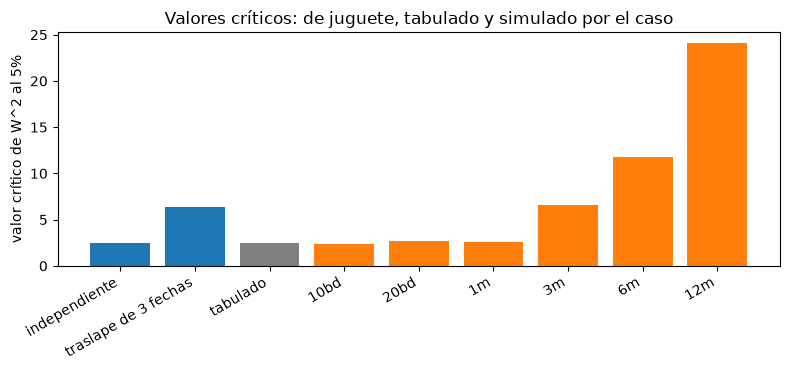

In [12]:
# Dibujar el valor crítico de 5% de los generadores de juguete, el valor tabulado y los seis horizontes del caso
names = list(toy) + ["tabulado"] + [h["horizon"] for h in horizons]
heights = list(toy.values()) + [vc.IID_CRITICAL_VALUES[0.05]] + crits
colors = ["tab:blue"] * 2 + ["grey"] + ["tab:orange"] * len(horizons)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(range(len(names)), heights, color=colors)
ax.set_xticks(range(len(names)), names, rotation=30, ha="right")
ax.set_ylabel("valor crítico de W^2 al 5%")
ax.set_title("Valores críticos: de juguete, tabulado y simulado por el caso")
fig.tight_layout()
plt.show()

La primera barra, PIT independientes, cae en el valor tabulado de 2,49, lo que muestra que la maquinaria de simulación reproduce una respuesta conocida. La segunda barra, un traslape de tres fechas, ya es más del doble de alta. Las barras naranjas son los valores propios del caso: se quedan cerca del tabulado en los horizontes hasta un mes y suben para 3, 6 y 12 meses, a la par de la pérdida de tamaño efectivo de muestra. Las barras de juguete ilustran la dirección del efecto y no son una calibración de él.

### Paso 6: el conteo de excedencias, una fila secundaria

La forma más antigua de hacer una prueba retrospectiva de una exposición es contar cuántas veces el valor realizado supera el pronóstico de PFE. La prueba de razón de verosimilitud de Kupiec compara el conteo de excepciones $x$ entre $n$ fechas con la tasa esperada $1 - q$; depende solo de $x$ y $n$. BCBS 185 (párrafo 27) advierte que esos criterios suponen excepciones independientes y que los datos traslapados lo rompen, así que el motor lleva la advertencia en la fila y Contraste marca la fila como secundaria. Como la prueba depende solo del conteo, podemos reconstruir una fila desde los conteos de excedencias versionados, con arreglos que tienen exactamente $x$ excepciones. La celda siguiente lo hace para el horizonte de 10 días, y luego imprime el W² de las tres subventanas de la cartera.

In [13]:
# Las filas de Kupiec del horizonte de 10 días reconstruidas desde los conteos de excedencias, y W^2 por subventana
h10 = horizons[0]
print(f"{'q':>5s}{'x':>5s}{'esperado':>10s}{'LR':>10s}{'p-value':>12s}{'luz':>8s}")
for e in h10["exceedances"]:
    n, x, q = h10["n"], e["count"], e["quantile"]
    t6 = vc.pfe_exceedance_backtest(np.concatenate([np.ones(x), np.zeros(n - x)]), np.full(n, 0.5), q)
    print(f"{q:5.2f}{x:5d}{e['expected']:10.1f}{t6.statistic:10.3f}{t6.p_value:12.2e}{LIGHT[t6.light.value]:>8s}")
caveat = "sí" if "paragraph 27" in t6.extras["caveat"] else "no"
print("la fila lleva la advertencia de BCBS 185 párrafo 27:", caveat)
first = bt["sub_windows"][0]["results"]
print(f"{'subventana':14s}" + "".join(f"{res['horizon']:>9s}" for res in first))
for w in bt["sub_windows"]:
    cells = "".join(f"{res['w2']:9.1f}" for res in w["results"])
    print(f"{w['window']:14s}" + cells, f"  (n = {w['results'][0]['n']})")

    q    x  esperado        LR     p-value     luz
 0.90   97      30.9   106.856    4.79e-25    rojo
 0.95   84      15.5   164.782    1.02e-37    rojo
 0.99   58       3.1   240.829    2.59e-54    rojo
la fila lleva la advertencia de BCBS 185 párrafo 27: sí
subventana         10bd     20bd       1m       3m       6m      12m
before-2008        77.1     75.8     71.4     74.8     69.9    118.4   (n = 96)
2008-2019          21.1     14.6     19.4     30.4     52.7    111.0   (n = 144)
from-2020          29.8     24.7     20.3     24.0     23.6     44.8   (n = 69)


## Resultados

**Respuesta:** El motor es internamente correcto y el modelo falla frente al mercado. La EE analítica coincide con la simulación dentro de 0,89 errores estándar de Monte Carlo (umbral 3), los recálculos de EEPE y CVA se ponen rojos cuando el número informado está 1% demasiado alto, y duplicar las trayectorias de 10.000 a 20.000 mueve la EE en 0,79 errores estándar. Sin embargo la prueba retrospectiva da $W^2$ de 107,7 a 10 días y 153,1 a 12 meses, frente a valores críticos simulados de 5% de 2,39 y 24,05, y en el horizonte de 10 días 31,4% de los PIT están sobre 0,90 donde se esperaría 10%.

- **El documento de un vistazo.** De las 42 filas versionadas de la variante de swap único, las cinco verificaciones internas (EE analítica, martingala, recálculo de EEPE y CVA, convergencia de trayectorias) están verdes, las cuatro comparaciones con QuantLib y las tres filas de ORE están verdes (notebook 07), y las 30 filas de la prueba retrospectiva están rojas: 12 filas PIT y 18 de excedencias.
- **EE analítica.** En las 19 fechas de reinicio la mayor brecha absoluta es 1.161 USD. A un año la EE analítica es 141.685 y la simulada 141.414; a cinco años 295.711 y 294.524, una diferencia de 0,4%.
- **Martingala.** La media del bono a 10 años descontado es 0,65861 a cinco años frente a $P(0,10) = 0,658648$; la mayor brecha estandarizada es 0,16 y la mayor brecha absoluta 7e-5.
- **Recálculo.** La EEPE y el CVA del documento son iguales a los recalculados desde el perfil (diferencia relativa 0). Informados 1% más altos, cada prueba devuelve una diferencia relativa de 1e-2 y una luz roja, así que el umbral de 1e-9 sí discrimina.
- **Convergencia.** La EEPE es 86.021, 87.117 y 87.551 con 5.000, 10.000 y 20.000 trayectorias, y el CVA 10.332 (+/- 111), 10.352 (+/- 79) y 10.338 (+/- 56). El cambio de 10.000 a 20.000 trayectorias es 0,79 errores estándar del perfil y 0,19 del CVA: verde.
- **La prueba retrospectiva rechaza el modelo en todos los horizontes.** $W^2$ es 107,7, 91,0, 89,8, 97,6, 95,9 y 153,1 de 10 días a 12 meses, frente a valores críticos simulados de 5% de 2,39, 2,73, 2,54, 6,58, 11,81 y 24,05. La tabla independiente (2,492) sería la vara equivocada desde 3 meses: el tamaño efectivo de muestra cae de 309 a 134,8, 76,5 y 54,8 a medida que los horizontes se traslapan, y el valor crítico simulado sube con él. La misma prueba sobre la propia tasa a 3 meses da 34,8 a 10 días, así que la dinámica de la tasa también se rechaza.
- **Dónde falla.** En el horizonte de 10 días 31,4% de los PIT están sobre 0,90 y 18,8% sobre 0,99 (un PIT uniforme da 10% y 1%), y 28,8% están bajo 0,10: el modelo es demasiado estrecho. Las filas de Kupiec coinciden: 97 excepciones de la PFE de 90% en 309 fechas contra 30,9 esperadas, 84 contra 15,5 a 95% y 58 contra 3,1 a 99%. La advertencia de BCBS 185 rige para estas filas: los conteos suponen independencia.
- **Leyendo los generadores de juguete.** PIT independientes dan un valor simulado de 5% de 2,50, el 2,49 tabulado; PIT de una ventana traslapada de tres fechas dan 6,39 con un tamaño efectivo de muestra de 110.

Lo que este notebook no muestra: el generador propio del caso para los valores críticos (versionado, no vuelto a correr), la comparación con ORE y QuantLib (notebook 07), ni una reparación del modelo: recalibrar sobre una ventana o cambiar la clase de modelo es una decisión de modelación fuera de esta validación.

## Resumen

- Un modelo de exposición se verifica de tres maneras: contra su forma cerrada (EE analítica), contra sus propias identidades (martingala, recálculo) y contra sí mismo con más trayectorias (convergencia); cada una tiene un umbral en errores estándar de Monte Carlo o una tolerancia relativa, y un umbral que no puede fallar no sirve, así que el notebook hace fallar a dos de ellos.
- La prueba retrospectiva de mercado transforma cada valor realizado en un PIT dentro de la distribución simulada y mide la uniformidad con el $W^2$ de Anderson-Darling; los horizontes traslapados vuelven dependientes a los PIT, así que los valores críticos se simulan bajo el modelo y la tabla independiente se muestra solo junto a ellos.
- El modelo de Hull-White versionado pasa todas las verificaciones internas y falla todas las pruebas retrospectivas: se rechaza en los seis horizontes, a 10 días los resultados realizados caen en las colas de tres a diecinueve veces más a menudo de lo esperado, y $W^2$ sigue grande en cada subventana.
- Los conteos de Kupiec coinciden con la prueba PIT y llevan la advertencia de BCBS 185 sobre la dependencia.

**Qué probar después.** Reemplaza el 0,5 de los arreglos de excedencias por otros pronósticos y mira cómo el estadístico de Kupiec depende solo del conteo; cambia el largo de ventana del generador traslapado a 6 y compara su valor de 5% con el versionado de 6 meses. Luego sigue con el notebook 07.

## Referencias

- BCBS (2010), Sound practices for backtesting counterparty credit risk models, publication 185. https://www.bis.org/publ/bcbs185.htm
- Formenti, L., Spadafora, L., Terraneo, F. and Ramponi, A., Probability integral transform and Anderson-Darling backtests, arXiv 1505.04593. https://arxiv.org/abs/1505.04593
- BCBS, Basel Framework, CRE53 Internal model method for counterparty credit risk (in force 2023-01-01, published 2020-06-05). https://www.bis.org/basel_framework/chapter/CRE/53.htm?inforce=20230101&published=20200605
- Hull, J. and White, A. (2012), CVA and wrong way risk, Financial Analysts Journal 68(5), 58-69. https://doi.org/10.2469/faj.v68.n5.6